# 02. Master Table: one row per eligible student, features from the first 28 days only

**Goal.** Turn the 7 raw OULAD tables into one analysis-ready table, with a documented audit trail.

**Design rules (set before looking at outcomes)**

1. **Unit:** one student in one course-presentation.
2. **Prediction time:** day `CUTOFF_DAY` (default 28) of the presentation. Every feature uses only information dated *before* the cutoff.
3. **Population:** students still registered at the cutoff. Students who unregistered earlier have already left, so there is nothing left to predict, and including them would leak the outcome.
4. **Target:** `target_at_risk` = 1 if `final_result` is Fail or Withdrawn, else 0 (Pass or Distinction).
5. **No learned preprocessing here** (no imputation of means, scaling, encoding fitted on data). Those steps are fitted on training data only in later notebooks.
6. The raw files are never modified. Every change is written to the transformation log.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
CUTOFF_DAY = 28          # prediction time: features may only use days < CUTOFF_DAY
N_TOP_ACTIVITY_TYPES = 6 # VLE activity types kept as separate click columns, rest go to "other"

RAW = Path("../data/raw")
PROC = Path("../data/processed")
OUT = Path("../outputs")
FIG = OUT / "figures"
for p in (PROC, OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)

KEY = ["code_module", "code_presentation", "id_student"]
MP = ["code_module", "code_presentation"]
NA = ["?"]  # OULAD encodes missing values as the string "?"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

# Transformation log: one row per material decision.
LOG = []
def log_step(step, table, issue, action, rows_affected, rationale, check):
    LOG.append(dict(step=step, table=table, issue=issue, action=action,
                    rows_affected=rows_affected, rationale=rationale, verification=check))

## 1. Load raw tables and take the "before" snapshot

In [2]:
courses = pd.read_csv(RAW / "courses.csv", na_values=NA)
assessments = pd.read_csv(RAW / "assessments.csv", na_values=NA)
vle = pd.read_csv(RAW / "vle.csv", na_values=NA)
info = pd.read_csv(RAW / "studentInfo.csv", na_values=NA)
reg = pd.read_csv(RAW / "studentRegistration.csv", na_values=NA)
sa = pd.read_csv(RAW / "studentAssessment.csv", na_values=NA)

# Compact dtypes keep the 10.6M-row click log at roughly 150 MB.
student_vle = pd.read_csv(
    RAW / "studentVle.csv",
    dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32",
           "id_site": "int32", "date": "int16", "sum_click": "int16"},
)

tables = {"courses": courses, "assessments": assessments, "vle": vle, "studentInfo": info,
          "studentRegistration": reg, "studentAssessment": sa, "studentVle": student_vle}
before = pd.DataFrame([
    dict(table=n, rows=len(d), cols=d.shape[1], missing_cells=int(d.isna().sum().sum()),
         exact_duplicate_rows=int(d.duplicated().sum()))
    for n, d in tables.items()
]).set_index("table")
before

,rows,cols,missing_cells,exact_duplicate_rows
table,,,,
courses,22,3,0,0
assessments,206,6,11,0
vle,6364,6,10486,0
studentInfo,32593,12,1111,0
studentRegistration,32593,5,22566,0
studentAssessment,173912,5,173,0
studentVle,10655280,6,0,787170


In [3]:
log_step("S1", "all", 'Missing values stored as the string "?" (object dtype in numeric columns)',
         'Read every CSV with na_values=["?"]', int(before.missing_cells.sum()),
         "Without this, date and score columns are strings and every numeric summary is wrong",
         "dtypes of date_registration, date_unregistration, score, date are numeric after load")

n_dup = int(before.loc["studentVle", "exact_duplicate_rows"])
dup_keys = int(student_vle.duplicated(KEY + ["id_site", "date"]).sum())
print(f"studentVle exact duplicate rows: {n_dup:,}")
print(f"studentVle rows sharing (student, site, day): {dup_keys:,}")
log_step("S2", "studentVle", "Exact duplicate rows and repeated (student, site, day) keys in the click log",
         "Kept all rows; clicks are summed", dup_keys,
         "Repeated keys are plausibly separate visits to the same page on one day, and the dataset documentation does not call them errors. Dropping them would under-count engagement.",
         "Sensitivity check planned in notebook 03: compare features with and without exact duplicates")

studentVle exact duplicate rows: 787,170
studentVle rows sharing (student, site, day): 2,195,960


## 2. Key checks (assertions)

Everything downstream assumes these hold. A failure stops the notebook.

In [4]:
assert not info.duplicated(KEY).any(), "studentInfo key not unique"
assert not reg.duplicated(KEY).any(), "studentRegistration key not unique"
assert not sa.duplicated(["id_assessment", "id_student"]).any(), "studentAssessment key not unique"
assert assessments.id_assessment.is_unique and vle.id_site.is_unique
assert not vle.duplicated(["id_site", "code_module", "code_presentation"]).any()

base = info.merge(reg, on=KEY, how="outer", validate="one_to_one", indicator=True)
assert (base["_merge"] == "both").all(), "studentInfo and studentRegistration do not match 1:1"
base = base.drop(columns="_merge")

# Metadata states 32,953 students in section 5 but its class table totals 32,593.
log_step("S3", "OULAD.names", "Metadata says 32,953 students in one place and 32,593 in the class table",
         "Used the observed row count (32,593) as the truth", 360,
         "Row count is verifiable from the data", f"len(studentInfo) = {len(info):,}")
print(f"{len(base):,} student-presentation rows, {base.id_student.nunique():,} distinct students")

32,593 student-presentation rows, 28,785 distinct students


## 3. Choosing and justifying the cutoff

`date_unregistration` is measured in days from the presentation start. If many students leave before the cutoff,
a late cutoff would remove a large part of the at-risk group from the problem. This table shows the trade-off.

In [5]:
AT_RISK = ["Fail", "Withdrawn"]
print("Everyone with an unregistration date is Withdrawn? ->")
print(pd.crosstab(base.final_result, base.date_unregistration.notna(), rownames=["final_result"], colnames=["has unregistration date"]))

rows = []
for c in (0, 14, 28, 42, 56):
    eligible = base[~(base.date_unregistration < c)]
    rows.append(dict(cutoff_day=c, eligible_students=len(eligible),
                     excluded_early_leavers=len(base) - len(eligible),
                     at_risk_rate=round(eligible.final_result.isin(AT_RISK).mean(), 3)))
pd.DataFrame(rows).set_index("cutoff_day")

Everyone with an unregistration date is Withdrawn? ->
has unregistration date  False  True 
final_result                         
Distinction               3024      0
Fail                      7043      9
Pass                     12361      0
Withdrawn                   93  10063


,eligible_students,excluded_early_leavers,at_risk_rate
cutoff_day,,,
0,29915,2678,0.486
14,28128,4465,0.453
28,27553,5040,0.442
42,27034,5559,0.431
56,26532,6061,0.420


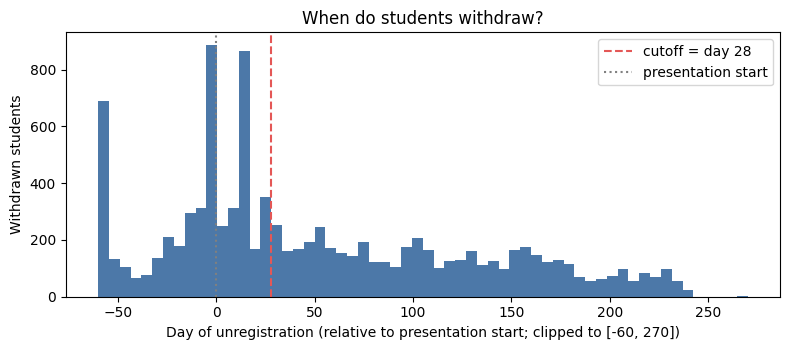

50.0% of withdrawn students leave before day 28; 2,676 leave before the course even starts.


In [6]:
w = base.loc[base.final_result == "Withdrawn", "date_unregistration"].dropna()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(w.clip(-60, 270), bins=60, color="#4C78A8")
ax.axvline(CUTOFF_DAY, color="#E45756", linestyle="--", label=f"cutoff = day {CUTOFF_DAY}")
ax.axvline(0, color="grey", linestyle=":", label="presentation start")
ax.set_xlabel("Day of unregistration (relative to presentation start; clipped to [-60, 270])")
ax.set_ylabel("Withdrawn students")
ax.set_title("When do students withdraw?")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "02_withdrawal_timing.png", dpi=150)
plt.show()
share_before = (w < CUTOFF_DAY).mean()
print(f"{share_before:.1%} of withdrawn students leave before day {CUTOFF_DAY}; {(w < 0).sum():,} leave before the course even starts.")

**Reading.** A large share of withdrawals happen before day 28, and thousands before day 0. Those students are not part of an
"identify risk at day 28" problem: the system already knows they left. They are removed from the modelling population, **not** from the dataset,
and the exclusion is quantified below. A later notebook can study early leavers as a separate question.

In [7]:
early_leavers = base.date_unregistration < CUTOFF_DAY
n_excl = int(early_leavers.sum())

# Source inconsistencies discovered while checking the rule "unregistered => Withdrawn"
n_unreg_not_wd = int((base.date_unregistration.notna() & (base.final_result != "Withdrawn")).sum())
n_early_not_wd = int((early_leavers & (base.final_result != "Withdrawn")).sum())
n_wd_no_date = int(((base.final_result == "Withdrawn") & base.date_unregistration.isna()).sum())
print(f"has unregistration date but final_result is not Withdrawn: {n_unreg_not_wd} (of which before the cutoff: {n_early_not_wd})")
print(f"final_result is Withdrawn but unregistration date is missing: {n_wd_no_date}")

pop = base.loc[~early_leavers].copy()
log_step("S4", "studentInfo+studentRegistration", f"Students who unregistered before day {CUTOFF_DAY} are not a valid prediction target",
         "Excluded from the modelling population by the date rule, whatever their label (rows kept in raw data)", n_excl,
         "They were no longer enrolled at prediction time. Keeping them would leak the label.",
         f"population = {len(pop):,}; {n_early_not_wd} excluded rows are labelled Fail rather than Withdrawn (see S4b)")
log_step("S4b", "studentInfo+studentRegistration", f"{n_unreg_not_wd} students have an unregistration date but final_result is not Withdrawn (documentation says unregistered means Withdrawn)",
         "Rule applied to the date, not the label; remaining cases (left after the cutoff) kept", n_unreg_not_wd,
         "The date is the direct evidence of leaving; the label may reflect a different recording rule",
         "cross-tab printed above")
log_step("S4c", "studentInfo+studentRegistration", f"{n_wd_no_date} Withdrawn students have no unregistration date, so their exit time is unknown",
         "Kept in the population; NOT flagged in the master table (a flag derived from the outcome would leak it)", n_wd_no_date,
         "Cannot verify they were enrolled at day 28. Small share; listed as a limitation and checked in a sensitivity run later.",
         "share of population reported in notebook 03")
print(f"excluded early leavers: {n_excl:,}  |  modelling population: {len(pop):,}")

n_reg_missing = int(pop.date_registration.isna().sum())
n_late = int((pop.date_registration >= CUTOFF_DAY).sum())
print(f"date_registration missing: {n_reg_missing}  |  registered on/after day {CUTOFF_DAY}: {n_late}")

has unregistration date but final_result is not Withdrawn: 9 (of which before the cutoff: 8)
final_result is Withdrawn but unregistration date is missing: 93
excluded early leavers: 5,040  |  modelling population: 27,553
date_registration missing: 7  |  registered on/after day 28: 18


## 4. Engagement features from the click log (days before the cutoff)

In [8]:
sv = student_vle[student_vle["date"] < CUTOFF_DAY].copy()
print(f"click rows before day {CUTOFF_DAY}: {len(sv):,} of {len(student_vle):,} ({len(sv) / len(student_vle):.1%})")
assert sv["date"].max() < CUTOFF_DAY  # leakage guard

# Object keys so the merges below do not trip over categorical dtypes.
sv = sv.astype({"code_module": "object", "code_presentation": "object"})
sv = sv.merge(vle[["id_site", "code_module", "code_presentation", "activity_type"]],
              on=["id_site", "code_module", "code_presentation"], how="left", validate="many_to_one")
n_no_type = int(sv.activity_type.isna().sum())
print("clicks with unknown activity_type:", n_no_type)

# Totals
g = sv.groupby(KEY)
clicks = g.agg(clicks_total=("sum_click", "sum"), active_days=("date", "nunique"),
               n_sites=("id_site", "nunique"), first_click_day=("date", "min"))

# By week: days < 0 are pre-start, then w1 = days 0-6, w2 = 7-13, ...
n_weeks = int(np.ceil(CUTOFF_DAY / 7))
period = np.where(sv["date"] < 0, "prestart", "w" + ((sv["date"] // 7) + 1).astype(str))
sv["period"] = period
weekly = sv.groupby(KEY + ["period"]).sum_click.sum().unstack(fill_value=0)
weekly = weekly.reindex(columns=["prestart"] + [f"w{i}" for i in range(1, n_weeks + 1)], fill_value=0)
weekly.columns = [f"clicks_{c}" for c in weekly.columns]

# By activity type: keep the most-clicked types, group the rest
type_totals = sv.groupby("activity_type").sum_click.sum().sort_values(ascending=False)
top_types = list(type_totals.head(N_TOP_ACTIVITY_TYPES).index)
sv["activity_group"] = np.where(sv.activity_type.isin(top_types), sv.activity_type, "other")
by_type = sv.groupby(KEY + ["activity_group"]).sum_click.sum().unstack(fill_value=0)
by_type.columns = [f"clicks_{c}" for c in by_type.columns]

print("top activity types kept:", top_types)
engage = clicks.join(weekly).join(by_type).reset_index()
engage.shape

click rows before day 28: 2,801,311 of 10,655,280 (26.3%)


clicks with unknown activity_type: 0


top activity types kept: ['forumng', 'oucontent', 'homepage', 'quiz', 'subpage', 'resource']


(28774, 19)

In [9]:
# Consistency check: the weekly columns must add up to the total
week_cols = [c for c in engage.columns if c.startswith("clicks_") and c.split("_")[1] in ("prestart",) + tuple(f"w{i}" for i in range(1, n_weeks + 1))]
type_cols = [c for c in by_type.columns]
assert (engage[week_cols].sum(axis=1) == engage.clicks_total).all()
assert (engage[type_cols].sum(axis=1) == engage.clicks_total).all()
print("weekly and activity-type columns both reconcile to clicks_total")

log_step("S5", "studentVle", f"Raw click log has 10.6M rows and no student-level features",
         f"Filtered to date < {CUTOFF_DAY}; aggregated to student-presentation: total, active days, distinct sites, first click day, clicks per period, clicks per activity type (top {N_TOP_ACTIVITY_TYPES} + other)",
         len(engage), "Only pre-cutoff behaviour may be a feature",
         f"max click date used = {int(sv['date'].max())} (< {CUTOFF_DAY}); weekly and type columns sum to clicks_total")

weekly and activity-type columns both reconcile to clicks_total


## 5. Early assessment features

Two different dates exist: the **due date** of an assessment (`assessments.date`, known in advance from the course schedule)
and the **submission date** (`date_submitted`, an outcome of student behaviour). Submissions after the cutoff are never used.
Banked results (`is_banked == 1`) are scores carried over from a previous attempt, not work done in this presentation, so they are excluded from behaviour features.

In [10]:
sa_full = sa.merge(assessments[["id_assessment", "code_module", "code_presentation", "assessment_type", "date", "weight"]]
                   .rename(columns={"date": "due_date"}),
                   on="id_assessment", how="left", validate="many_to_one")
assert sa_full.code_module.notna().all(), "submission without a matching assessment"

n_banked = int((sa_full.is_banked == 1).sum())
early = sa_full[(sa_full.date_submitted < CUTOFF_DAY) & (sa_full.is_banked == 0)].copy()
early["due_by_cutoff"] = (early.due_date < CUTOFF_DAY).astype(int)
assert early.date_submitted.max() < CUTOFF_DAY

early_feat = early.groupby(KEY).agg(
    n_assess_submitted=("id_assessment", "size"),
    n_due_submitted=("due_by_cutoff", "sum"),
    mean_score_early=("score", "mean"),
).reset_index()

due = (assessments[assessments.date < CUTOFF_DAY].groupby(MP).size().rename("n_assess_due").reset_index())

print(f"banked rows (excluded from behaviour features): {n_banked:,}")
print(f"submissions before day {CUTOFF_DAY}: {len(early):,} by {len(early_feat):,} student-presentations")
print("modules with an assessment due before the cutoff:")
print(due.groupby("code_module").n_assess_due.max().to_string())

log_step("S6", "studentAssessment", "Submission and score columns include post-cutoff submissions and banked scores from earlier attempts",
         f"Kept only date_submitted < {CUTOFF_DAY} and is_banked == 0; built n_assess_submitted, n_due_submitted, mean_score_early; merged module-level n_assess_due from the schedule",
         len(early), "Later submissions leak the outcome; banked scores are not this presentation's behaviour",
         f"max date_submitted used = {int(early.date_submitted.max())}")

banked rows (excluded from behaviour features): 1,909
submissions before day 28: 23,439 by 20,185 student-presentations
modules with an assessment due before the cutoff:
code_module
AAA    1
BBB    1
CCC    1
DDD    2
FFF    1


**Important limitation.** Early assessment evidence only exists for modules that schedule an assessment before the cutoff.
Modules EEE and GGG schedule no assessment before day 28 (see the module list above), so early assessment features are structurally empty for them.
For the other five modules the cutoff leaves only one or two assessments, so those features are thin even there.
Missing is therefore *informative by design* here: it is handled with explicit zeros and indicators, not with imputed scores.

## 6. Background (demographic) cleaning

In [11]:
cat_cols = ["gender", "region", "highest_education", "imd_band", "age_band", "disability", "final_result"]
for c in cat_cols:
    pop[c] = pop[c].astype("string").str.strip()

# imd_band mixes "10-20" with "10-20%"; normalise to a consistent label
raw_imd = pop.imd_band.copy()
pop["imd_band"] = pop.imd_band.str.replace("%", "", regex=False)
n_imd_fixed = int((raw_imd != pop.imd_band).sum())
print("imd_band labels before:", sorted(raw_imd.dropna().unique()))
print("imd_band labels after :", sorted(pop.imd_band.dropna().unique()))

IMD_ORDER = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80", "80-90", "90-100"]
EDU_ORDER = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent", "HE Qualification", "Post Graduate Qualification"]
AGE_ORDER = ["0-35", "35-55", "55<="]
assert set(pop.imd_band.dropna()) <= set(IMD_ORDER)
assert set(pop.highest_education) <= set(EDU_ORDER)
assert set(pop.age_band) <= set(AGE_ORDER)

pop["imd_missing"] = pop.imd_band.isna().astype(int)
pop["imd_order"] = pop.imd_band.map({v: i for i, v in enumerate(IMD_ORDER)})      # 0 = most deprived, NaN kept as missing
pop["edu_level"] = pop.highest_education.map({v: i for i, v in enumerate(EDU_ORDER)})
pop["age_order"] = pop.age_band.map({v: i for i, v in enumerate(AGE_ORDER)})

log_step("S7", "studentInfo", 'imd_band uses two label styles ("10-20" and "10-20%")',
         "Removed the % sign so all labels share one style", n_imd_fixed,
         "Otherwise the same band is treated as different categories", f"imd_band has {pop.imd_band.nunique()} distinct non-missing labels")
log_step("S8", "studentInfo", "imd_band missing for some students",
         "Kept as missing and added imd_missing flag; no imputation at this stage", int(pop.imd_missing.sum()),
         "Imputation must be fitted on training data only. Missingness may itself be informative (check in notebook 03).",
         "imd_missing + non-missing = population size")
log_step("S9", "studentInfo", "Ordered categories stored as text",
         "Added ordinal codes imd_order, edu_level, age_order and kept original text columns", len(pop),
         "Preserves ordinal meaning for models and correlation without discarding labels", "mapping covers every observed label (asserted)")

# cohort and course-length context
pop["year"] = pop.code_presentation.str[:4].astype(int)
pop["start_term"] = pop.code_presentation.str[4]
pop["cohort_order"] = pop.code_presentation.map({"2013B": 0, "2013J": 1, "2014B": 2, "2014J": 3})
pop = pop.merge(courses, on=MP, how="left", validate="many_to_one")
assert pop.cohort_order.notna().all() and pop.module_presentation_length.notna().all()

pop["reg_date_missing"] = pop.date_registration.isna().astype(int)
pop["late_registrant"] = (pop.date_registration >= CUTOFF_DAY).astype(int)
log_step("S10", "studentRegistration", "date_registration missing for a few students",
         "Left missing and added reg_date_missing flag", int(pop.reg_date_missing.sum()),
         "Too few to impute meaningfully; the flag keeps them visible", "count of flagged rows reported")

imd_band labels before: ['0-10%', '10-20', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
imd_band labels after : ['0-10', '10-20', '20-30', '30-40', '40-50', '50-60', '60-70', '70-80', '80-90', '90-100']


## 7. Assemble the master table

In [12]:
master = (pop
          .merge(engage, on=KEY, how="left", validate="one_to_one")
          .merge(early_feat, on=KEY, how="left", validate="one_to_one")
          .merge(due, on=MP, how="left", validate="many_to_one"))

# Students without any click or submission rows: no log rows means zero recorded activity (a true zero).
count_cols = [c for c in master.columns if c.startswith("clicks_")] + ["active_days", "n_sites"]
no_vle = master.clicks_total.isna()
master["no_vle_activity"] = no_vle.astype(int)
master[count_cols] = master[count_cols].fillna(0).astype(int)
master["n_assess_due"] = master.n_assess_due.fillna(0).astype(int)
master[["n_assess_submitted", "n_due_submitted"]] = master[["n_assess_submitted", "n_due_submitted"]].fillna(0).astype(int)
# first_click_day and mean_score_early stay missing: "no click" / "nothing submitted" is not a number.
master["submit_rate_early"] = np.where(master.n_assess_due > 0, master.n_due_submitted / master.n_assess_due.where(master.n_assess_due > 0), np.nan)

log_step("S11", "master", "Students with no click rows or no early submissions after the left joins",
         "Count features set to 0 and no_vle_activity flag added; first_click_day, mean_score_early and submit_rate_early left missing",
         int(no_vle.sum()), "Absence of log rows means zero recorded activity. A score or first-click day does not exist, so it stays missing.",
         "clicks_total >= 0 everywhere; no_vle_activity == (clicks_total == 0)")

# Target. final_result is kept only as a label source, with names that make misuse obvious.
master = master.rename(columns={"final_result": "target_final_result"})
master["target_at_risk"] = master.target_final_result.isin(AT_RISK).astype(int)

# Drop post-outcome and redundant fields from the modelling table
master = master.drop(columns=["date_unregistration"])
log_step("S12", "master", "date_unregistration is only recorded for students who withdraw (post-outcome information)",
         "Dropped from the master table", len(master), "Direct target leakage", "column absent from master")

feature_first = ["code_module", "code_presentation", "id_student"]
master = master[feature_first + [c for c in master.columns if c not in feature_first]]
master.shape

(27553, 46)

## 8. Validation checks

In [13]:
assert not master.duplicated(KEY).any(), "master key not unique"
assert len(master) == len(pop)
assert master.target_at_risk.notna().all()
assert (master.clicks_total >= 0).all()
assert (master.no_vle_activity == (master.clicks_total == 0)).all()
assert "date_unregistration" not in master.columns

# Leakage guard: nothing outside the cutoff window was used.
assert sv["date"].max() < CUTOFF_DAY and early.date_submitted.max() < CUTOFF_DAY

# Bivariate sanity check: preprocessing should not have destroyed the engagement signal
print("At-risk rate by early engagement quartile (clicks_total), should fall as engagement rises:")
q = pd.qcut(master.clicks_total.rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
print(master.groupby(q, observed=True).target_at_risk.mean().round(3).to_string())

# Subgroup check: exclusions must not have erased any module or cohort
print("\nPopulation per cohort and module (rows kept / rows originally):")
orig = info.groupby(MP).size().rename("original")
kept = master.groupby(MP).size().rename("kept")
cmp_ = pd.concat([orig, kept], axis=1)
cmp_["kept_share"] = (cmp_.kept / cmp_.original).round(3)
print(cmp_.to_string())
assert cmp_.kept.notna().all()

At-risk rate by early engagement quartile (clicks_total), should fall as engagement rises:
clicks_total
Q1 low     0.625
Q2         0.484
Q3         0.386
Q4 high    0.271

Population per cohort and module (rows kept / rows originally):
                               original  kept  kept_share
code_module code_presentation                            
AAA         2013J                   383   370       0.966
            2014J                   365   348       0.953
BBB         2013B                  1767  1531       0.866
            2013J                  2237  1835       0.820
            2014B                  1613  1282       0.795
            2014J                  2292  1787       0.780
CCC         2014B                  1936  1500       0.775
            2014J                  2498  2023       0.810
DDD         2013B                  1303  1146       0.880
            2013J                  1938  1648       0.850
            2014B                  1228  1030       0.839
         

In [14]:
print("At-risk rate in raw population (all rows)      :", round(info.final_result.isin(AT_RISK).mean(), 3))
print("At-risk rate in modelling population (day 28+) :", round(master.target_at_risk.mean(), 3))
print()
print(pd.crosstab(master.code_presentation, master.target_final_result, margins=True))

At-risk rate in raw population (all rows)      : 0.528
At-risk rate in modelling population (day 28+) : 0.442

target_final_result  Distinction  Fail   Pass  Withdrawn    All
code_presentation                                              
2013B                        327  1241   1768        795   4131
2013J                        749  1993   3726       1219   7687
2014B                        784  1833   2574       1325   6516
2014J                       1164  1977   4293       1785   9219
All                         3024  7044  12361       5124  27553


**Reading the two checks.** Engagement and risk should be strongly and monotonically related, which confirms the aggregation kept the signal.
The cohort and module table shows how much each group lost to the early-leaver exclusion. The at-risk rate is lower after the exclusion,
because the clearest withdrawals are removed. This is why results must always be quoted for the day-28 population and never compared directly with a full-course failure rate.

## 9. Before and after

In [15]:
after = pd.DataFrame([dict(table="master (analysis-ready)", rows=len(master), cols=master.shape[1],
                           missing_cells=int(master.isna().sum().sum()),
                           exact_duplicate_rows=int(master.duplicated().sum()))]).set_index("table")
summary = pd.concat([before.loc[["studentInfo", "studentRegistration", "studentAssessment", "studentVle"]], after])
summary

,rows,cols,missing_cells,exact_duplicate_rows
table,,,,
studentInfo,32593,12,1111,0
studentRegistration,32593,5,22566,0
studentAssessment,173912,5,173,0
studentVle,10655280,6,0,787170
master (analysis-ready),27553,46,15767,0


In [16]:
miss = master.isna().sum()
miss[miss > 0].to_frame("missing").assign(pct=lambda d: (d.missing / len(master) * 100).round(1))

,missing,pct
imd_band,1029,3.7
date_registration,7,0.0
imd_order,1029,3.7
first_click_day,940,3.4
mean_score_early,7771,28.2
submit_rate_early,4991,18.1


## 10. Data dictionary for the master table

In [17]:
D = []
def d(var, meaning, typ, role, valid, notes=""):
    D.append(dict(variable=var, meaning_unit=meaning, type_scale=typ, role=role, valid_values=valid, quality_notes=notes))

d("code_module", "Course module code", "Categorical; nominal", "Key / context", "AAA to GGG (7)", "Part of the unit key")
d("code_presentation", "Presentation: year + B (Feb) or J (Oct)", "Categorical; nominal", "Key / context", "2013B, 2013J, 2014B, 2014J", "Used for the temporal split")
d("id_student", "Anonymised student id", "Identifier", "Identifier", "integer", "Never a feature; one person can appear in several presentations")
d("gender", "Declared gender", "Categorical; nominal", "Predictor / fairness group", "M, F", "")
d("region", "Region of residence during the presentation", "Categorical; nominal", "Predictor", "13 UK regions", "High cardinality for rare-event models; check group sizes")
d("highest_education", "Highest education on entry", "Categorical; ordinal", "Predictor / fairness group", "5 levels", "Rare levels: No Formal quals, Post Graduate")
d("edu_level", "Ordinal code of highest_education", "Numerical; ordinal", "Predictor", "0 to 4", "0 = No Formal quals")
d("imd_band", "Index of Multiple Deprivation band of residence", "Categorical; ordinal", "Predictor / fairness group", "0-10 to 90-100", f"Labels harmonised ({n_imd_fixed} rows); missing kept")
d("imd_order", "Ordinal code of imd_band", "Numerical; ordinal", "Predictor", "0 to 9", "0 = most deprived; missing kept as NaN")
d("imd_missing", "Flag: imd_band missing", "Binary", "Predictor", "0/1", "Missingness may be informative")
d("age_band", "Age band", "Categorical; ordinal", "Predictor / fairness group", "0-35, 35-55, 55<=", "55<= is very small")
d("age_order", "Ordinal code of age_band", "Numerical; ordinal", "Predictor", "0 to 2", "")
d("disability", "Declared disability", "Binary", "Predictor / fairness group", "Y, N", "Sensitive attribute")
d("num_of_prev_attempts", "Previous attempts at this module", "Numerical; count", "Predictor", "0 to 6", "Heavily right-skewed; most are 0")
d("studied_credits", "Credits being studied across modules", "Numerical; ratio", "Predictor", "30 to 655", "Long right tail; verify very large values in notebook 03")
d("date_registration", "Days from presentation start to registration (negative = before start)", "Numerical; interval", "Predictor", "integer", "Few missing; reg_date_missing flag")
d("reg_date_missing", "Flag: date_registration missing", "Binary", "Predictor", "0/1", "")
d("late_registrant", f"Registered on or after day {CUTOFF_DAY}", "Binary", "Predictor", "0/1", "Very few students, little early data")
d("year", "Presentation year", "Numerical; interval", "Context / split", "2013, 2014", "")
d("start_term", "B (February) or J (October) start", "Categorical; nominal", "Context", "B, J", "")
d("cohort_order", "Chronological order of presentation", "Numerical; ordinal", "Split variable", "0 to 3", "Used for temporal train/test split")
d("module_presentation_length", "Length of the presentation in days", "Numerical; ratio", "Context", "234 to 269", "")
d("clicks_total", f"Total VLE clicks before day {CUTOFF_DAY}", "Numerical; count", "Predictor", ">= 0", "Heavily right-skewed; consider log transform")
d("active_days", f"Distinct days with at least one click before day {CUTOFF_DAY}", "Numerical; count", "Predictor", f"0 to {CUTOFF_DAY + 25}", "Includes pre-start days")
d("n_sites", "Distinct VLE materials used", "Numerical; count", "Predictor", ">= 0", "")
d("first_click_day", "Day of the first click (negative = before start)", "Numerical; interval", "Predictor", "integer", "Missing when the student has no clicks")
for c in [c for c in master.columns if c.startswith("clicks_") and c != "clicks_total"]:
    part = c.replace("clicks_", "")
    d(c, f"Clicks in period/activity '{part}'", "Numerical; count", "Predictor", ">= 0", "Right-skewed; periods and types each sum to clicks_total")
d("no_vle_activity", "Flag: no clicks at all before cutoff", "Binary", "Predictor", "0/1", "True zero activity")
d("n_assess_due", "Assessments scheduled to be due before the cutoff (module level)", "Numerical; count", "Context", "0 to several", "Zero for modules with no early assessment")
d("n_assess_submitted", "Assessments submitted before the cutoff (excludes banked)", "Numerical; count", "Predictor", ">= 0", "")
d("n_due_submitted", "Submitted before the cutoff among those due before it", "Numerical; count", "Predictor", ">= 0", "")
d("submit_rate_early", "n_due_submitted / n_assess_due", "Numerical; ratio", "Predictor", "0 to 1", "Missing when nothing was due")
d("mean_score_early", "Mean score of early submissions", "Numerical; interval", "Predictor", "0 to 100", "Missing when nothing submitted; do not impute with a mean before the split")
d("target_final_result", "Final course result (label source only)", "Categorical; nominal", "Target source", "Distinction, Pass, Fail, Withdrawn", "Never a feature")
d("target_at_risk", "1 if Fail or Withdrawn, else 0", "Binary", "Target", "0/1", "Positive class is the focus; check imbalance")

dictionary = pd.DataFrame(D)
missing_in_dict = set(master.columns) - set(dictionary.variable)
extra_in_dict = set(dictionary.variable) - set(master.columns)
assert not missing_in_dict and not extra_in_dict, (missing_in_dict, extra_in_dict)
dictionary

,variable,meaning_unit,type_scale,role,valid_values,quality_notes
0,code_module,Course module code,Categorical; nominal,Key / context,AAA to GGG (7),Part of the unit key
1,code_presentation,Presentation: year + B (Feb) or J (Oct),Categorical; nominal,Key / context,"2013B, 2013J, 2014B, 2014J",Used for the temporal split
2,id_student,Anonymised student id,Identifier,Identifier,integer,Never a feature; one person can appear in seve...
3,gender,Declared gender,Categorical; nominal,Predictor / fairness group,"M, F",
4,region,Region of residence during the presentation,Categorical; nominal,Predictor,13 UK regions,High cardinality for rare-event models; check ...
5,highest_education,Highest education on entry,Categorical; ordinal,Predictor / fairness group,5 levels,"Rare levels: No Formal quals, Post Graduate"
6,edu_level,Ordinal code of highest_education,Numerical; ordinal,Predictor,0 to 4,0 = No Formal quals
7,imd_band,Index of Multiple Deprivation band of residence,Categorical; ordinal,Predictor / fairness group,0-10 to 90-100,Labels harmonised (23696 rows); missing kept
8,imd_order,Ordinal code of imd_band,Numerical; ordinal,Predictor,0 to 9,0 = most deprived; missing kept as NaN
9,imd_missing,Flag: imd_band missing,Binary,Predictor,0/1,Missingness may be informative


## 11. Save outputs

In [18]:
out_name = f"oulad_master_day{CUTOFF_DAY}.csv"
master.to_csv(PROC / out_name, index=False)
dictionary.to_csv(OUT / "data_dictionary_master.csv", index=False)
log_df = pd.DataFrame(LOG)
log_df.to_csv(OUT / "transformation_log.csv", index=False)

check = pd.read_csv(PROC / out_name)
assert check.shape == master.shape
print("saved:", PROC / out_name, check.shape)
log_df[["step", "table", "issue", "action", "rows_affected"]]

saved: ..\data\processed\oulad_master_day28.csv (27553, 46)


,step,table,issue,action,rows_affected
0,S1,all,"Missing values stored as the string ""?"" (objec...","Read every CSV with na_values=[""?""]",34347
1,S2,studentVle,"Exact duplicate rows and repeated (student, si...",Kept all rows; clicks are summed,2195960
2,S3,OULAD.names,"Metadata says 32,953 students in one place and...","Used the observed row count (32,593) as the truth",360
3,S4,studentInfo+studentRegistration,Students who unregistered before day 28 are no...,Excluded from the modelling population by the ...,5040
4,S4b,studentInfo+studentRegistration,9 students have an unregistration date but fin...,"Rule applied to the date, not the label; remai...",9
5,S4c,studentInfo+studentRegistration,93 Withdrawn students have no unregistration d...,Kept in the population; NOT flagged in the mas...,93
6,S5,studentVle,Raw click log has 10.6M rows and no student-le...,Filtered to date < 28; aggregated to student-p...,28774
7,S6,studentAssessment,Submission and score columns include post-cuto...,Kept only date_submitted < 28 and is_banked ==...,23439
8,S7,studentInfo,"imd_band uses two label styles (""10-20"" and ""1...",Removed the % sign so all labels share one style,23696
9,S8,studentInfo,imd_band missing for some students,Kept as missing and added imd_missing flag; no...,1029


## 12. Open issues and assumptions for later notebooks

- **Cutoff is a modelling choice.** Results are conditional on day 28. A sensitivity analysis over other cutoffs is cheap because the notebook is parameterised by `CUTOFF_DAY`.
- **Early assessments are structurally missing for some modules.** Module-level differences must be reported, and models need an indicator rather than imputation.
- **Repeated students** (same person in several presentations) mean random row splits would leak. Use the temporal split (train 2013, test 2014) and group-aware cross-validation.
- **Click duplicates were kept.** Notebook 03 should test whether removing exact duplicates changes the engagement features materially.
- **Outliers** (`clicks_total`, `studied_credits`) are retained here. They need domain checks before any capping.
- **All learned steps** (imputation, scaling, encoding, resampling) are deferred until after the train/test split.